## Chapter 4: Implementing a GPT model from scratch to generate text

Implementing a small GPT-2 model with 124 million parameters

### 4.1 Coding an LLM

In [1]:
# Config

GPT_CONFIG_124M = {
    "vocab_size": 50257,    # Vocabulary size
    "context_length": 1024, # Context length, number of input tokens
    "emb_dim": 768,         # Embedding dimension, transforms each token into a 768-dimensional vector
    "n_heads": 12,          # Number of attention heads in multi-head attention mechanism
    "n_layers": 12,         # Number of layers, number of transformer blocks in the model
    "drop_rate": 0.1,       # Dropout rate
    "qkv_bias": False       # Query-Key-Value bias, whether to include a bias vector in the linear layers
}

In [2]:
# Placeholder for GPT model architecture
import torch
import torch.nn as nn

class DummyGPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.tok_emb    = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb    = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop_emb   = nn.Dropout(cfg["drop_rate"])
        self.trf_blocks = nn.Sequential(*[DummyTransformerBlock(cfg) for _ in range(cfg["n_layers"])]) # Placeholder transformer block
        self.final_norm = DummyLayerNorm(cfg["emb_dim"]) # Placeholder LayerNorm
        self.out_head   = nn.Linear(cfg["emb_dim"], cfg["vocab_size"], bias=False)

    def forward(self, in_idx):
        batch_size, seq_len = in_idx.shape
        tok_embeds = self.tok_emb(in_idx)
        pos_embeds = self.pos_emb(torch.arange(seq_len, device=in_idx.device))

        x = tok_embeds + pos_embeds
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)
        return logits

class DummyTransformerBlock(nn.Module): # Placeholder transformer class
    def __init__(self, cfg):
        super().__init__()

    def forward(self, x):
        return x

class DummyLayerNorm(nn.Module): # Placeholder LayerNorm class
    def __init__(self, normalized_shape, eps=1e-5):
        super().__init__()

    def forward(self, x):
        return x

In [3]:
import tiktoken

tokenizer   = tiktoken.get_encoding("gpt2")
batch       = []
txt1        = "Every effort moves you"
txt2        = "Every day holds a"

batch.append(torch.tensor(tokenizer.encode(txt1)))
batch.append(torch.tensor(tokenizer.encode(txt2)))
batch = torch.stack(batch, dim=0)
print(batch)

tensor([[6109, 3626, 6100,  345],
        [6109, 1110, 6622,  257]])


In [4]:
torch.manual_seed(123)
model   = DummyGPTModel(GPT_CONFIG_124M)
logits  = model(batch)
print("Output has shape: ", logits.shape)
print(logits) 

Output has shape:  torch.Size([2, 4, 50257])
tensor([[[-1.2034,  0.3201, -0.7130,  ..., -1.5548, -0.2390, -0.4667],
         [-0.1192,  0.4539, -0.4432,  ...,  0.2392,  1.3469,  1.2430],
         [ 0.5307,  1.6720, -0.4695,  ...,  1.1966,  0.0111,  0.5835],
         [ 0.0139,  1.6755, -0.3388,  ...,  1.1586, -0.0435, -1.0400]],

        [[-1.0908,  0.1798, -0.9484,  ..., -1.6047,  0.2439, -0.4530],
         [-0.7860,  0.5581, -0.0610,  ...,  0.4835, -0.0077,  1.6621],
         [ 0.3567,  1.2698, -0.6398,  ..., -0.0162, -0.1296,  0.3717],
         [-0.2407, -0.7349, -0.5102,  ...,  2.0057, -0.3694,  0.1814]]],
       grad_fn=<UnsafeViewBackward0>)


### 4.2 Normalizing activation with layer normalization
Deep networks will struggle with vanishing or exploding gradients if we don't  normalize

In [5]:
torch.manual_seed(123)
batch_example = torch.randn(2, 5)
layer = nn.Sequential(nn.Linear(5, 6), nn.ReLU())
out = layer(batch_example)
print(out)

tensor([[0.2260, 0.3470, 0.0000, 0.2216, 0.0000, 0.0000],
        [0.2133, 0.2394, 0.0000, 0.5198, 0.3297, 0.0000]],
       grad_fn=<ReluBackward0>)


In [6]:
mean = out.mean(dim=-1, keepdim=True)
var  = out.var(dim=-1, keepdim=True)
print(f"Mean:\n{mean}\nVariance:\n{var}")

Mean:
tensor([[0.1324],
        [0.2170]], grad_fn=<MeanBackward1>)
Variance:
tensor([[0.0231],
        [0.0398]], grad_fn=<VarBackward0>)


In [7]:
out_norm = (out - mean) / torch.sqrt(var)
mean = out_norm.mean(dim=-1, keepdim=True)
var = out_norm.var(dim=-1, keepdim=True)

print("Normalized layer outputs:\n", out_norm)
torch.set_printoptions(sci_mode=False)
print("Mean:\n", mean)
print("Variance:\n", var)

Normalized layer outputs:
 tensor([[ 0.6159,  1.4126, -0.8719,  0.5872, -0.8719, -0.8719],
        [-0.0189,  0.1121, -1.0876,  1.5173,  0.5647, -1.0876]],
       grad_fn=<DivBackward0>)
Mean:
 tensor([[0.0000],
        [0.0000]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[1.0000],
        [1.0000]], grad_fn=<VarBackward0>)


In [8]:
class LayerNorm(nn.Module):
    def __init__(self, emb_dim):
        super().__init__()
        self.eps    = 1e-5
        self.scale  = nn.Parameter(torch.ones(emb_dim))
        self.shift  = nn.Parameter(torch.zeros(emb_dim))

    def forward(self, x):
        mean    = x.mean(dim=-1, keepdim=True)
        var     = x.var(dim=-1, keepdim=True)
        norm_x  = (x - mean) / torch.sqrt(var + self.eps)
        return self.scale * norm_x + self.shift 

In [9]:
# Trying the layer norm module
ln = LayerNorm(emb_dim=5)
out_ln = ln(batch_example)
mean = out_ln.mean(dim=-1, keepdim=True)
var = out_ln.var(dim=-1, keepdim=True)
print("Mean: \n", mean)
print("Variance:\n", var)

Mean: 
 tensor([[-0.0000],
        [ 0.0000]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[1.0000],
        [1.0000]], grad_fn=<VarBackward0>)


### 4.3 Implementing a FFN with GELU activations
Historically ReLU has been commonly used in deep learning, however activation functions such as GELU (Gaussian error linear unit) and SwiGLU (Swish-gated linear unit) are more commonly used for LLms

In [10]:
"""
GELU(x) = x⋅Φ(x), where Φ(x) is the cumulative distribution function of the standard Gaussian distribution.
But it's common to use a computationally cheaper approximiation.
"""

class GELU(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return 0.5 * x * (1 + torch.tanh(
            torch.sqrt(torch.tensor(2.0 / torch.pi)) * 
            (x + 0.044715 * torch.pow(x, 3))
            ))

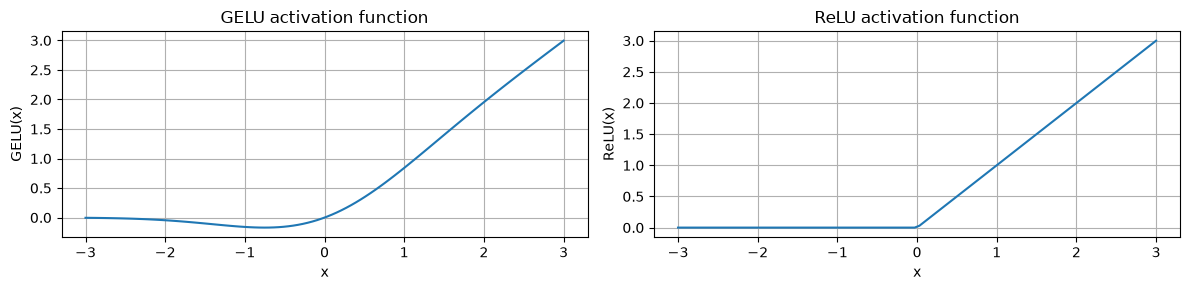

In [11]:
# Plot GELO compared to ReLU
import matplotlib.pyplot as plt
gelu = nn.GELU()
relu = nn.ReLU()

x = torch.linspace(-3, 3, 100)

y_gelu = gelu(x)
y_relu = relu(x)

plt.figure(figsize=(12, 3))

for i, (y, label) in enumerate(zip([y_gelu, y_relu], ["GELU", "ReLU"]), 1):
    plt.subplot(1, 2, i)

    plt.plot(x.detach(), y.detach())

    plt.title(f"{label} activation function")
    plt.xlabel("x")
    plt.ylabel(f"{label}(x)")
    plt.grid(True)

plt.tight_layout()
plt.show()

In [12]:
# Feed Forward Network module
class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(cfg["emb_dim"], 4 * cfg["emb_dim"]),
            GELU(),
            nn.Linear(4 * cfg["emb_dim"], cfg["emb_dim"])
        )

    def forward(self, x):
        return self.layers(x)

In [13]:
ffn = FeedForward(GPT_CONFIG_124M)
x   = torch.rand(2, 3, 768)
out = ffn(x)
print(out.shape)

torch.Size([2, 3, 768])


### 4.4 Adding Shortcut Connections
Shortcut connections are connections that skip layers in the network, mitigating the challenge of vanishing gradients. 

In [14]:
class ExampleDeepNeuralNetwork(nn.Module):

    def __init__(self, layer_sizes, use_shortcut):
        super().__init__()
        self.use_shortcut = use_shortcut
        self.layers = nn.ModuleList([
            nn.Sequential(nn.Linear(layer_sizes[0], layer_sizes[1]), 
                            GELU()),
            nn.Sequential(nn.Linear(layer_sizes[1], layer_sizes[2]),
                            GELU()),
            nn.Sequential(nn.Linear(layer_sizes[2], layer_sizes[3]),
                            GELU()),
            nn.Sequential(nn.Linear(layer_sizes[3], layer_sizes[4]),
                            GELU()),
            nn.Sequential(nn.Linear(layer_sizes[4], layer_sizes[5]),
                            GELU()),
        ])

    def forward(self, x):
        for layer in self.layers:
            layer_output = layer(x)
            if self.use_shortcut and x.shape == layer_output.shape:
                x = x + layer_output
            else:
                x = layer_output

        return x

In [15]:
layer_sizes  = [3, 3, 3, 3, 3, 1]
sample_input = torch.tensor([[1., 0., -1.]])
torch.manual_seed(123)
model_without_shortcut = ExampleDeepNeuralNetwork(layer_sizes, use_shortcut=False) 

def print_gradients(model, x):
    output = model(x)
    target = torch.tensor([[0.]])

    loss   = nn.MSELoss()
    loss   = loss(output, target)

    loss.backward()

    for name, param in model.named_parameters():
        if 'weight' in name:
            print(f"{name} has gradient mean of {param.grad.abs().mean().item()}")

print_gradients(model_without_shortcut, sample_input)

layers.0.0.weight has gradient mean of 0.00020173587836325169
layers.1.0.weight has gradient mean of 0.0001201116101583466
layers.2.0.weight has gradient mean of 0.0007152041653171182
layers.3.0.weight has gradient mean of 0.001398873864673078
layers.4.0.weight has gradient mean of 0.005049646366387606


In [16]:
torch.manual_seed(123)
model_with_shortcut = ExampleDeepNeuralNetwork(layer_sizes, use_shortcut=True) 

print_gradients(model_with_shortcut, sample_input)

layers.0.0.weight has gradient mean of 0.22169791162014008
layers.1.0.weight has gradient mean of 0.20694105327129364
layers.2.0.weight has gradient mean of 0.32896989583969116
layers.3.0.weight has gradient mean of 0.2665732204914093
layers.4.0.weight has gradient mean of 1.3258541822433472


### 4.5 Building Transformer Block
Connecting attention heads and linear layers to create transformer blocks

In [ ]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout, num_heads, qkv_bias=False):
        super().__init__()
        assert d_out % num_heads == 0, "d_out must be divisible by num_heads"

        self.d_out = d_out
        self.num_heads = num_heads
        self.head_dim = d_out // num_heads  # Reduce the projection dim to match desired output dim

        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.out_proj = nn.Linear(d_out, d_out)  # Linear layer to combine head outputs
        self.dropout = nn.Dropout(dropout)
        self.register_buffer("mask", torch.triu(torch.ones(context_length, context_length), diagonal=1))

    def forward(self, x):
        b, num_tokens, d_in = x.shape

        keys = self.W_key(x)  # Shape: (b, num_tokens, d_out)
        queries = self.W_query(x)
        values = self.W_value(x)

        # We implicitly split the matrix by adding a `num_heads` dimension
        # Unroll last dim: (b, num_tokens, d_out) -> (b, num_tokens, num_heads, head_dim)
        keys = keys.view(b, num_tokens, self.num_heads, self.head_dim)
        values = values.view(b, num_tokens, self.num_heads, self.head_dim)
        queries = queries.view(b, num_tokens, self.num_heads, self.head_dim)

        # Transpose: (b, num_tokens, num_heads, head_dim) -> (b, num_heads, num_tokens, head_dim)
        keys = keys.transpose(1, 2)
        queries = queries.transpose(1, 2)
        values = values.transpose(1, 2)

        # Compute scaled dot-product attention (aka self-attention) with a causal mask
        attn_scores = queries @ keys.transpose(2, 3)  # Dot product for each head

        # Original mask truncated to the number of tokens and converted to boolean
        mask_bool = self.mask.bool()[:num_tokens, :num_tokens]

        # Use the mask to fill attention scores
        attn_scores.masked_fill_(mask_bool, -torch.inf)

        attn_weights = torch.softmax(attn_scores / keys.shape[-1]**0.5, dim=-1)
        attn_weights = self.dropout(attn_weights)

        # Shape: (b, num_tokens, num_heads, head_dim)
        context_vec = (attn_weights @ values).transpose(1, 2)

        # Combine heads, where self.d_out = self.num_heads * self.head_dim
        context_vec = context_vec.contiguous().view(b, num_tokens, self.d_out)
        context_vec = self.out_proj(context_vec)  # optional projection

        return context_vec

# The MultiHeadAttention class from Chapter 3

In [68]:
class TransformerBlock(nn.Module):

    def __init__(self, cfg):
        super().__init__()
        self.att   = MultiHeadAttention(
            d_in=cfg["emb_dim"],
            d_out=cfg["emb_dim"],
            context_length=cfg["context_length"],
            num_heads=cfg["n_heads"],
            dropout=cfg["drop_rate_multihead"],
            qkv_bias=cfg["qkv_bias"]
        )
        self.ff    = FeedForward(cfg)
        self.norm1 = LayerNorm(emb_dim=cfg["emb_dim"])
        self.norm2 = LayerNorm(emb_dim=cfg["emb_dim"])
        self.drop_shortcut = nn.Dropout(cfg["drop_rate_shortcut"])

    def forward(self, x):
        shortcut = x
        x = self.norm1(x)
        x = self.att(x)
        x = self.drop_shortcut(x)
        x = x + shortcut

        shortcut = x
        x = self.norm2(x)
        x = self.ff(x)
        x = self.drop_shortcut(x)
        x = x + shortcut
        return x
    

In [21]:
torch.manual_seed(123)
x = torch.rand(2, 4, 768)
block = TransformerBlock(cfg=GPT_CONFIG_124M)
output = block(x)
print(f"Input has shape: {x.shape}\nOutput has shape: {output.shape}")


Input has shape: torch.Size([2, 4, 768])
Output has shape: torch.Size([2, 4, 768])


### 4.6 Coding a GPT Model
Now all the building blocks are done and we can construct the GPT model

In [69]:
class GPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.tok_emb    = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb    = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop_emb   = nn.Dropout(cfg["drop_rate_embedding"])

        self.trf_blocks = nn.Sequential(
            *[TransformerBlock(cfg) for _ in range(cfg["n_layers"])]
            )
        self.final_norm = LayerNorm(cfg["emb_dim"])
        self.out_head   = nn.Linear(
            cfg["emb_dim"], cfg["vocab_size"], bias=False
        )

    def forward(self, in_idx):
        batch_size, seq_len = in_idx.shape
        tok_embeds = self.tok_emb(in_idx)
        pos_embeds = self.pos_emb(torch.arange(seq_len, device=in_idx.device))

        x = tok_embeds + pos_embeds
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)

        logits = self.out_head(x)
        return logits


In [28]:
torch.manual_seed(123)

model = GPTModel(GPT_CONFIG_124M)
out = model(batch)
print(f"Input batch:\n {batch}\n\nOutput shape: {out.shape}\n")
print(out)

Input batch:
 tensor([[6109, 3626, 6100,  345],
        [6109, 1110, 6622,  257]])

Output shape: torch.Size([2, 4, 50257])

tensor([[[ 0.3612,  0.4223, -0.0709,  ...,  0.3479,  0.4655, -0.2833],
         [-0.1785, -0.5656, -0.9477,  ...,  0.0476,  0.5173, -0.3160],
         [ 0.7118,  0.0335,  0.1078,  ...,  0.1020, -0.4331, -0.2547],
         [-1.0068,  0.3420, -0.1191,  ...,  0.7193,  0.4018,  0.0532]],

        [[-0.2562,  0.0899,  0.0338,  ...,  0.2659,  0.4448, -0.6800],
         [ 0.1230,  0.3651, -0.2071,  ...,  0.7704,  0.2702,  0.2250],
         [ 1.0555,  1.0312, -0.2797,  ...,  0.6934,  0.3201, -0.3172],
         [-0.1559,  0.3922,  0.3286,  ...,  1.2627, -0.1862,  0.0391]]],
       grad_fn=<UnsafeViewBackward0>)


In [31]:
# Analyze number of parameters in model
total_params = sum(p.numel() for p in model.parameters())
print(f"Total amount of parameters: {total_params:,}")

Total amount of parameters: 163,009,536


In [32]:
print("Token embedding layer shape:", model.tok_emb.weight.shape)
print("Output layer shape:", model.out_head.weight.shape)

Token embedding layer shape: torch.Size([50257, 768])
Output layer shape: torch.Size([50257, 768])


In [ ]:
total_params_gpt2 = (
total_params - sum(p.numel()
for p in model.out_head.parameters())
)
print(f"Number of trainable parameters "
 f"considering weight tying: {total_params_gpt2:,}"
)

Number of trainable parameters considering weight tying: 124,412,160


In [34]:
# We have a discrepancy between total amount of parameters (163 million) and the 124 million we said from the beginning. 
# Since output layer and token embedding layer are very large and the same size, we can actually reuse the weights from the token embedding layer
# in the output layer to reduce overall memory and computation. This is called weight tying.
# However using different layers can result in higher performance.

In [46]:
# Exercise 4.1 Num parameters in feed forward and attention modules
print(f"Num parameters in feed forward module: {sum(p.numel() for p in model.trf_blocks[0].ff.parameters()):,}")
print(f"Num parameters in multi-head attention module: {sum(p.numel() for p in model.trf_blocks[0].att.parameters()):,}")

Num parameters in feed forward module: 4,722,432
Num parameters in multi-head attention module: 2,360,064


In [47]:
# Now we look at the memory requirements for 163 million parameters
total_size_bytes = total_params * 4 
total_size_mb    = total_size_bytes / (1024 * 1024)
print(f"Total size of the model is {total_size_mb:2f} MB")

Total size of the model is 621.832031 MB


In [55]:
# Exercise 4.2 Initializing larger models
GPT_MEDIUM_CONFIG = {
'vocab_size': 50257, 'context_length': 1024, 'emb_dim': 1024, 'n_heads': 16, 'n_layers': 24, 'drop_rate': 0.1, 'qkv_bias': False 
}
GPT_LARGE_CONFIG = {
'vocab_size': 50257, 'context_length': 1024, 'emb_dim': 1280, 'n_heads': 20, 'n_layers': 36, 'drop_rate': 0.1, 'qkv_bias': False 
}
GPT_2XL_CONFIG = {
'vocab_size': 50257, 'context_length': 1024, 'emb_dim': 1600, 'n_heads': 25, 'n_layers': 48, 'drop_rate': 0.1, 'qkv_bias': False 
}


In [56]:
torch.manual_seed(123)
configs = [GPT_MEDIUM_CONFIG, GPT_LARGE_CONFIG, GPT_2XL_CONFIG]
total_params_lst = []
for cfg in configs:
    model = GPTModel(cfg)
    total_params = sum(p.numel() for p in model.parameters())
    total_params_lst.append(total_params)

print(f"Medium config has {total_params_lst[0]:,} parameters\nLarge config has {total_params_lst[1]:,} parameters\n2XL config has {total_params_lst[2]:,} parameters")

Medium config has 406,212,608 parameters
Large config has 838,220,800 parameters
2XL config has 1,637,792,000 parameters


### 4.6 Generating Text
Now lets convert the tensor outputs to human readable text.

In [62]:
# Simple method to generate text

def generate_text_simple(model, idx, max_new_tokens, context_size):
    for _ in range(max_new_tokens):
        idx_cond = idx[:, -context_size:]
        with torch.no_grad():
            logits = model(idx_cond)
        logits = logits[:, -1, :] # Focus only on last timestep, so that (batch, n_token, vocab_size) -> (batch, vocab_size)
        probas = torch.softmax(logits, dim=-1) # Probabilities for token being a word in vocab
        idx_next = torch.argmax(probas, dim=-1, keepdim=True) # Find token with highest probability
        idx = torch.cat((idx, idx_next), dim=1) # Add token at last place in sequence for next prediction

    return idx

In [59]:
# Test generation function
start_context = "Hello, I am"
encoded = tokenizer.encode(start_context)
print("encoded", encoded)
encoded_tensor = torch.tensor(encoded).unsqueeze(0)
print("encoded_tensor shape: ", encoded_tensor.shape)

encoded [15496, 11, 314, 716]
encoded_tensor shape:  torch.Size([1, 4])


In [ ]:
torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)

In [64]:
# Put model into eval mode to disable random components like dropout
model.eval()
out = generate_text_simple(
    model=model,
    idx=encoded_tensor,
    max_new_tokens=6,
    context_size=GPT_CONFIG_124M["context_length"]
)
print("Output:", out)
print("Output length:", len(out[0]))

Output: tensor([[15496,    11,   314,   716, 27018, 24086, 47843, 30961, 42348,  7267]])
Output length: 10


In [65]:
# Now we can decode the output
decoded_text = tokenizer.decode(out.squeeze(0).tolist())
print(decoded_text)

Hello, I am Featureiman Byeswickattribute argue


In [67]:
UPDATED_GPT_CONFIG = {
    'vocab_size': 50257,
    'context_length': 1024,
    'emb_dim': 768,
    'n_heads': 12,
    'n_layers': 12,
    'drop_rate_embedding': 0.1,
    'drop_rate_shortcut': 0.1,
    'drop_rate_multihead': 0.1,
    'qkv_bias': False}

In [71]:
torch.manual_seed(123)
model = GPTModel(UPDATED_GPT_CONFIG)